In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as c
import numpy as np

In [2]:
sns.set_context("notebook")
sns.set_style("whitegrid")
sns.set_theme(

    rc={"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],

        "axes.labelsize": 13,
        "axes.titlesize": 15,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
        "legend.title_fontsize": 12,

        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.0})

This metadata file records technical information about signals that passed coninous signal DP, but not all passed windowed signal DP.

## upload metadata & have a first look

In [3]:
filepath = f"{c.META_DIR}/exams_processed_technical_info.csv"
df = pd.read_csv(filepath, encoding = 'utf-8')
df

,site,exam_id,initial_fs,n_all_windows,ch_non_eeg,status,ch_drop,ch_missing,n_good_windows,why_bad_windows
0,S00,20220512-163632-{24c1e4cc-f690-4174-8eae-b0d96...,250.0,150,"[""ECG"", ""RESP1"", ""RESP2""]",too short,[],[],149,"{'C4': 1, 'T4': 1}"
1,S00,20220512-164523-{3222752a-e1a1-439f-b7a7-85642...,250.0,150,[],ok,"[""S1"", ""S2"", ""S3"", ""S4""]",[],150,{}
2,S00,20220512-164615-{ee327e54-0056-41d9-84a4-a4243...,250.0,151,"[""ECG"", ""RESP1"", ""RESP2""]",ok,[],[],150,{'Fp2': 1}
3,S00,20220512-164352-{310806e9-34f6-4c9e-9478-1726b...,250.0,171,[],ok,"[""S1"", ""S2"", ""S3"", ""S4""]",[],170,"{'Fp1': 1, 'F3': 1, 'F4': 1, 'O1': 1}"
4,S00,20220512-164458-{30002f30-edb7-462f-b593-92e16...,250.0,150,"[""ECG"", ""RESP1"", ""RESP2""]",too short,[],[],149,{'F8': 1}
...,...,...,...,...,...,...,...,...,...,...
35849,S29,20220602-152957-{d652f74d-ea3e-4fcd-afe6-fa624...,250.0,200,[],ok,"[""A1"", ""A2"", ""EKG""]",[],189,"{'Fp2': 8, 'Fp1': 6, 'F7': 4, 'Cz': 1}"
35850,S29,20220602-152950-{328256db-ecb9-4880-aea3-cae0d...,250.0,200,[],ok,"[""A1"", ""A2"", ""EKG""]",[],199,{'Fp2': 1}
35851,S29,20220602-153022-{951c8fc9-e8b4-4a85-9c3b-c8cea...,250.0,200,[],ok,"[""A1"", ""A2"", ""EKG""]",[],199,{'Fp2': 1}
35852,S29,20220602-153237-{eec9357c-2477-4e02-a5f0-13641...,250.0,202,[],ok,"[""A1"", ""A2"", ""EKG""]",[],184,"{'Fp1': 16, 'Fp2': 4, 'F7': 1, 'P3': 1, 'P4': 1}"


## explore initial frequencies

In [4]:
df.columns = df.columns.str.strip()

initial_fs_by_site = df.groupby("site")["initial_fs"].agg(
    ["mean", "min", "max"]
)

initial_fs_by_site

,mean,min,max
site,,,
S00,250.022511,249.987501,251.000000
S01,250.004785,250.000000,251.000000
S02,274.929178,250.000000,300.000000
S03,249.987501,249.987501,249.987501
S04,261.517615,250.000000,600.000000
S05,250.000000,250.000000,250.000000
S06,250.000000,250.000000,250.000000
S07,250.000000,250.000000,250.000000
S08,250.000000,250.000000,250.000000


All recordings had initial sampling around 250Hz. In preprocessing all were downsampled to fs = 128Hz.

Text(0.5, 1.03, 'Distribution of preprocessed full lengths in windows')

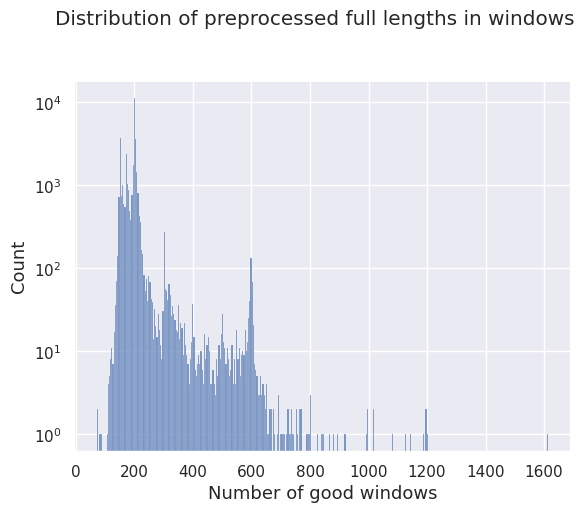

In [13]:
g = sns.histplot(x='n_good_windows', 
                data = df,
                )
#g.set(xlim=(0, 700))
g.set(yscale='log')
g.set(xlabel = 'Number of good windows')
g.figure.suptitle('Distribution of preprocessed full lengths in windows', y = 1.03)

Text(0.5, 1.03, 'Distribution of preprocessed full lengths in windows per site')

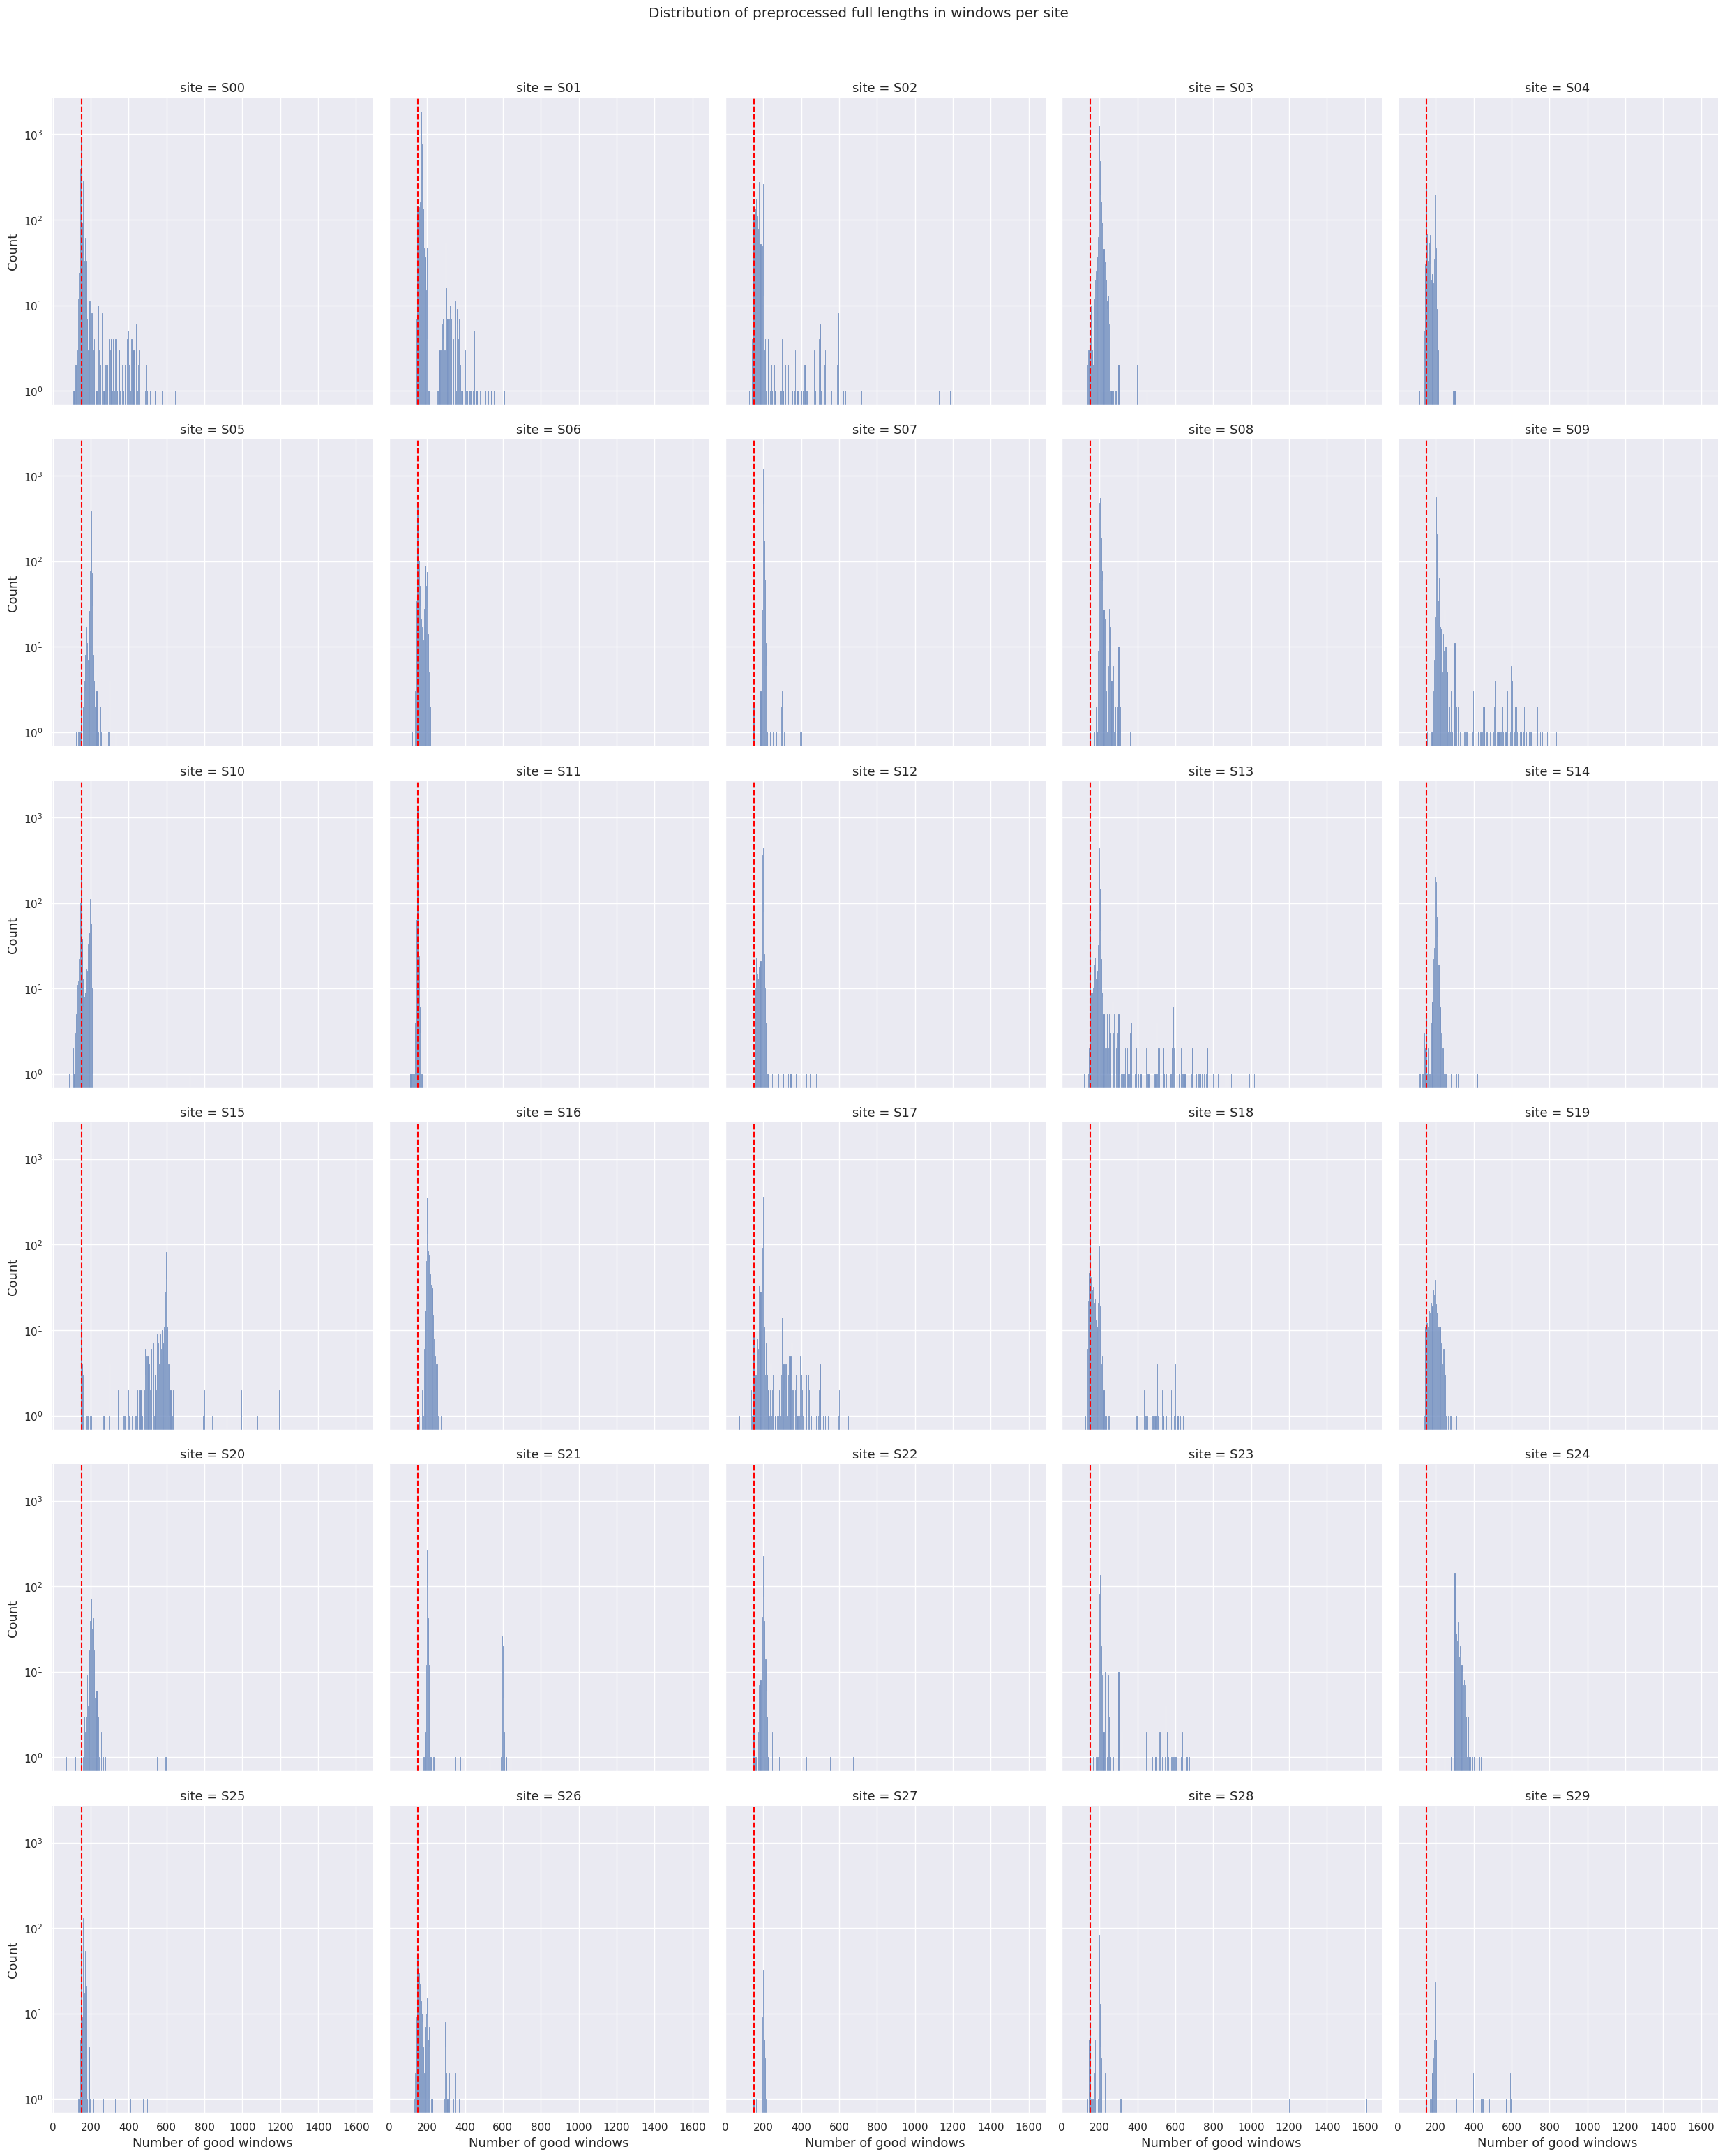

In [15]:
g = sns.displot(x='n_good_windows', 
                data = df,
                col = 'site',
                col_wrap = 5,
                facet_kws = {'sharex':True, 'sharey':True}
                )

#plot the chosen threshold
for ax in g.axes.flat:
    ax.axvline(150, color='red', linestyle='--', linewidth=1.5)


#g.set(xlim=(0, 700))
g.set(yscale='log')
g.set_axis_labels('Number of good windows', 'Count')
g.figure.suptitle('Distribution of preprocessed full lengths in windows per site', 
                  y = 1.03)

The exams that are shorter than 150 windows are discarded, so those that are to the left of threshold marker. The most "too short" recordings were in S00 & S10. Below the fraction that was discarded, because even processed (status "too short") is shown.

Text(0.5, 1.03, 'Distribution of status prior processing')

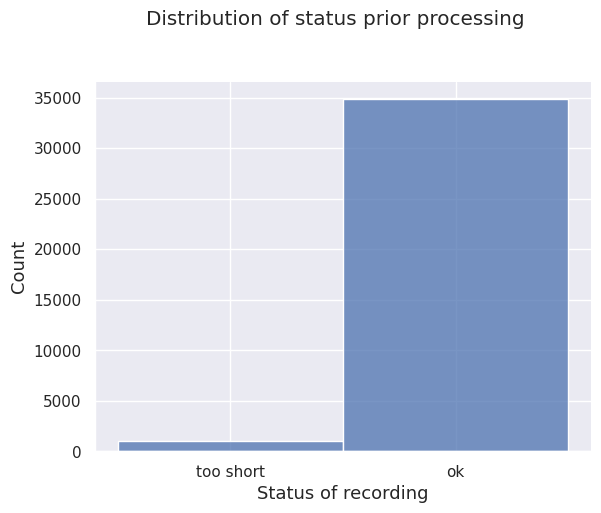

In [19]:
g = sns.histplot(x='status', 
                data = df,
                )
#g.set(xlim=(0, 700))
g.set(xlabel = 'Status of recording')
g.figure.suptitle('Distribution of status prior processing', y = 1.03)

Text(0.5, 1.03, 'Distribution of status prior processing per site')

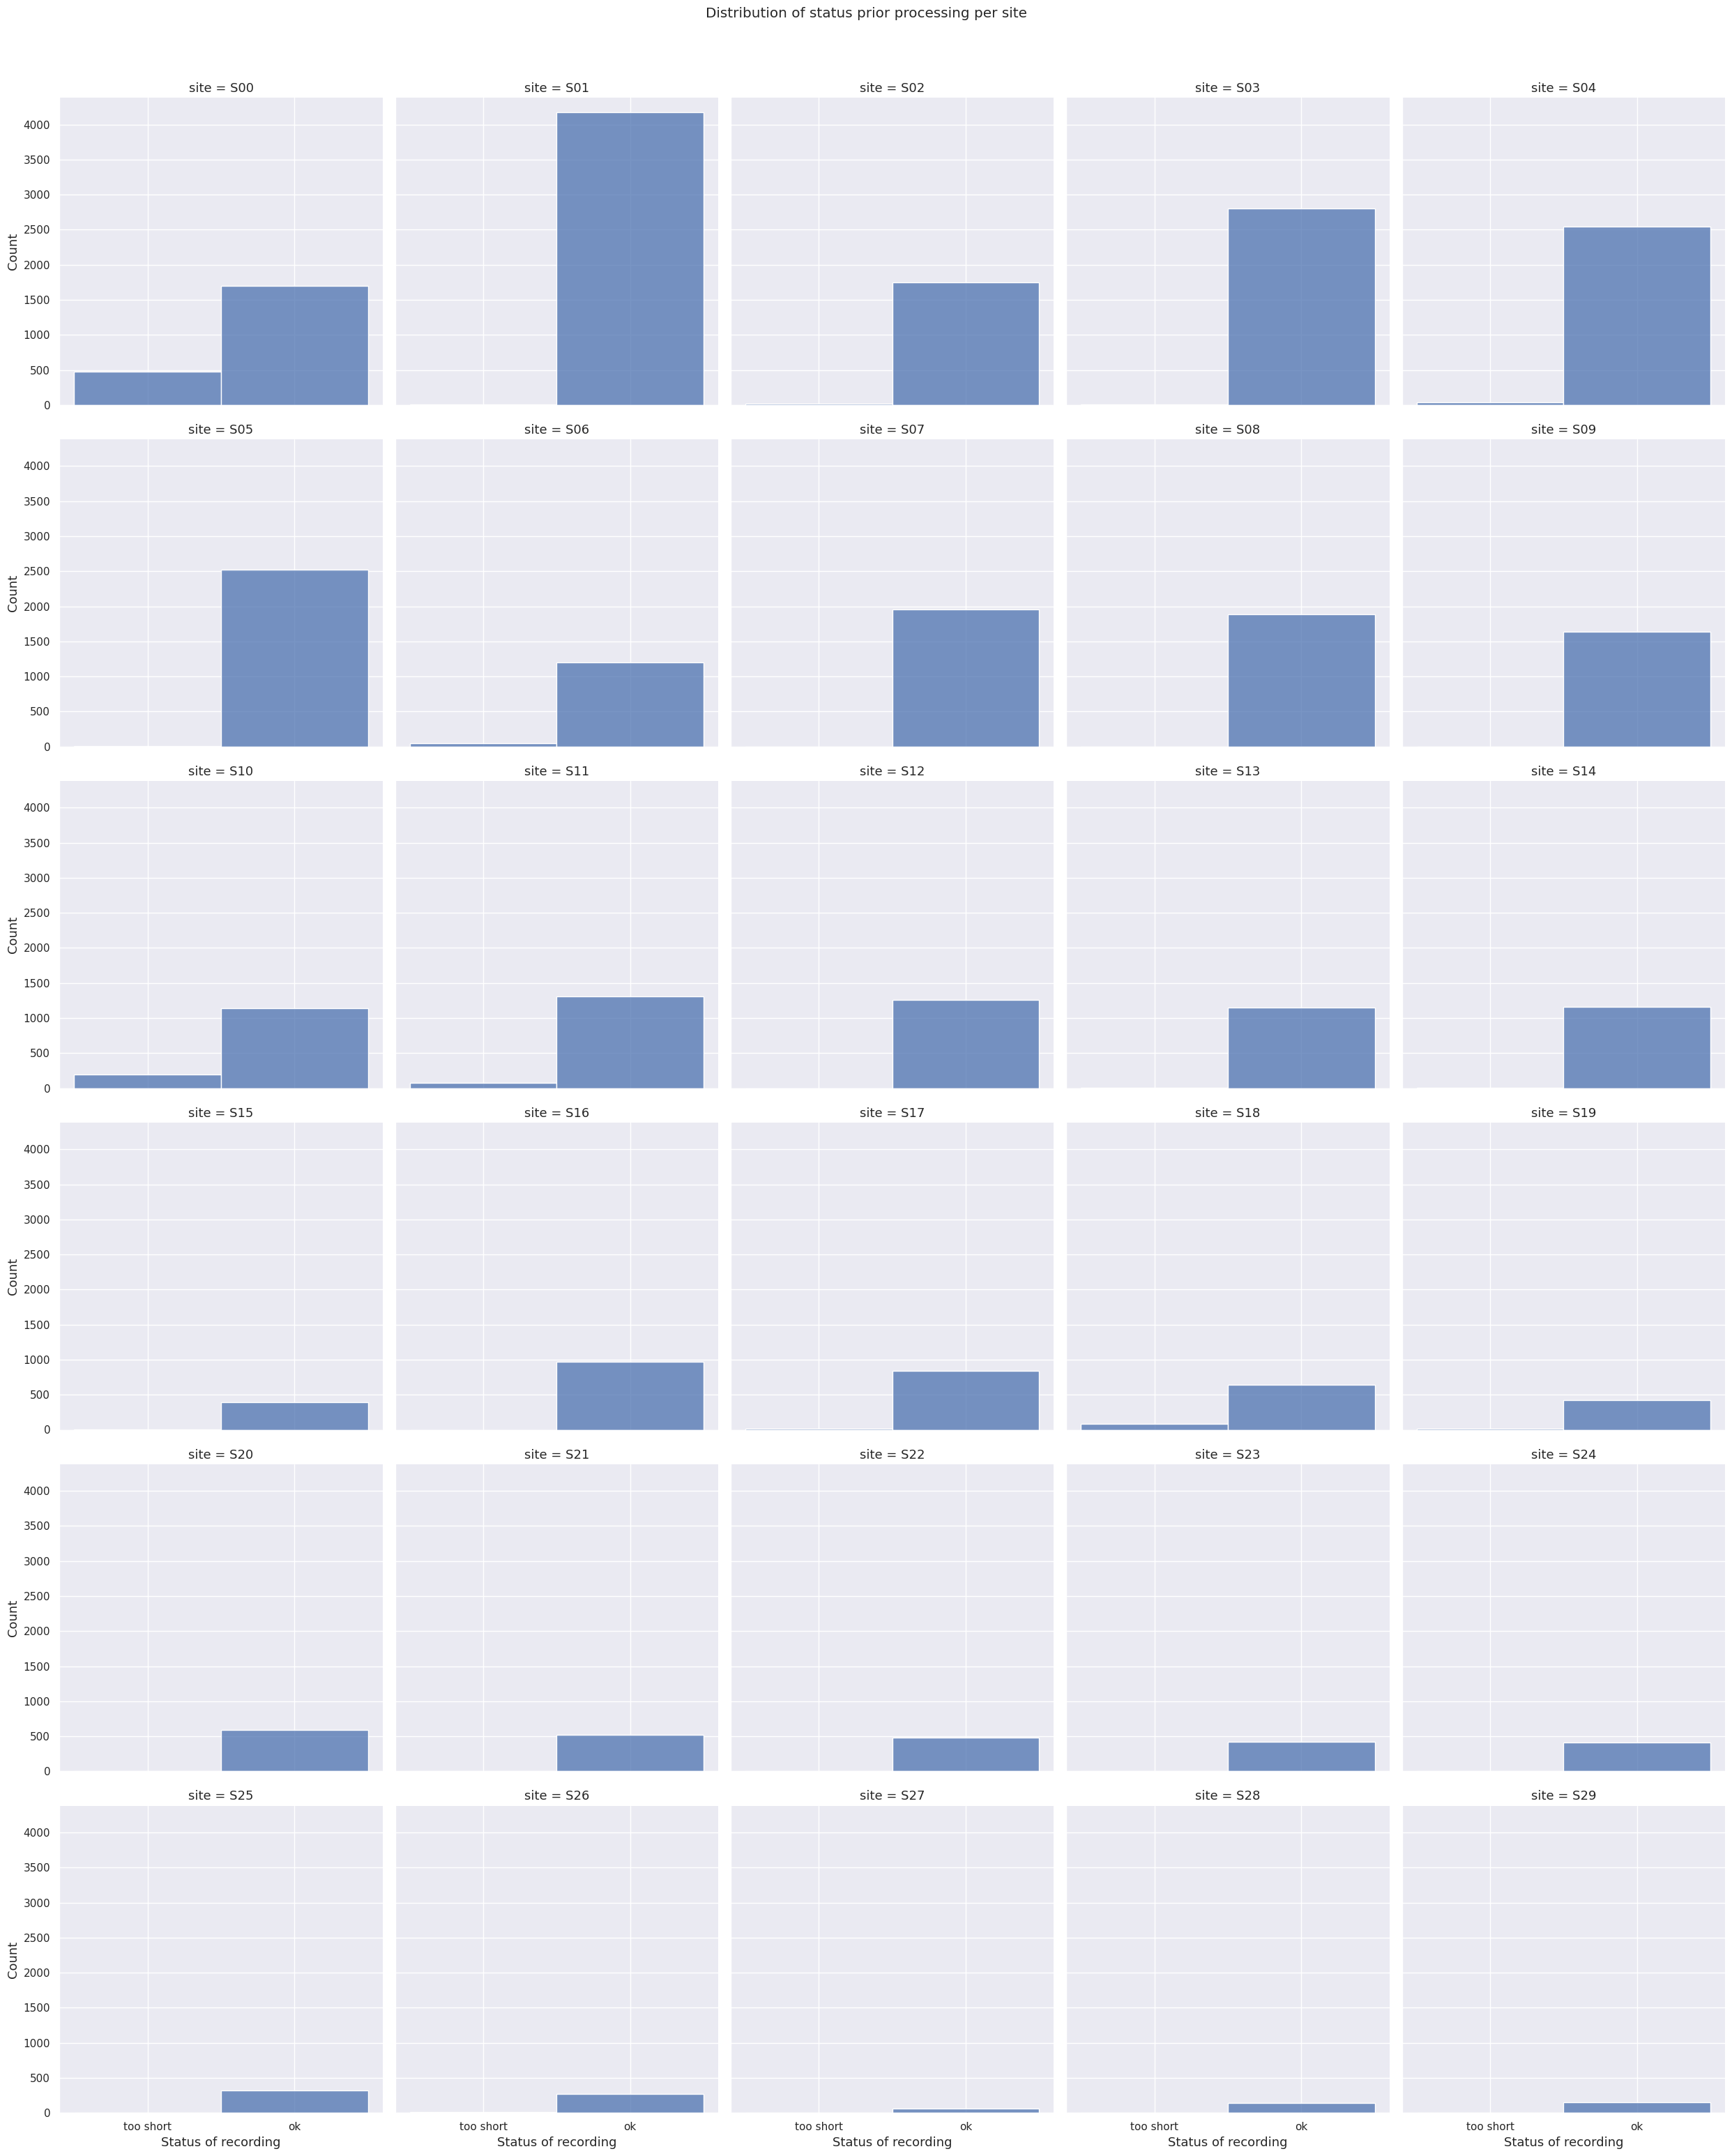

In [21]:
g = sns.displot(x='status', 
                data = df,
                col = 'site',
                col_wrap = 5,
                facet_kws = {'sharex':True, 'sharey':True}
                )

g.set_axis_labels('Status of recording', 'Count')
g.figure.suptitle('Distribution of status prior processing per site', 
                  y = 1.03)